# Fase 2: Comprensión de los Datos (EDA e Inspección de Calidad)

**Metodología:** CRISP-DM — Fase 2 (*Data Understanding*)  
**Entradas:** `data/01_raw/train-00000-of-00001.parquet` y `data/01_raw/test-00000-of-00001.parquet`  

---

## Objetivos de este Notebook
1. **Recolección Inicial:** Cargar las particiones `train` y `test` en formato `.parquet`, validar sus dimensiones, uso de memoria y tipos de datos (`dtypes`).
2. **Descripción de los Datos:** Clasificar las 20 columnas por naturaleza y rol analítico, y obtener estadísticos descriptivos univariados.
3. **Exploración de los Datos - EDA:** Analizar la distribución de `Time_taken (min)` y su relación bivariada y multivariada con variables de tráfico, clima, entregas múltiples, festivales, vehículo, ciudad y atributos del repartidor.
4. **Auditoría de Calidad / Ruido:** Cuantificar con exactitud valores nulos reales y strings `"NaN"`, formatos corruptos en horas (`0.xxx` y `24:XX`), anomalías geográficas (`(0.0, 0.0)` y signos negativos) y *outliers* en edad/calificaciones, justifiacando cada decisión de limpieza de la Fase 3.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Configuración de estilo visual
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

# Rutas del proyecto (soporta ejecución desde la raíz o desde notebooks/)
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT_DIR / "data" / "01_raw"
FIG_DIR = ROOT_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"ROOT_DIR: {ROOT_DIR}")
print(f"RAW_DIR : {RAW_DIR}")
print(f"FIG_DIR : {FIG_DIR}")


ROOT_DIR: c:\Users\perci\Desktop\9no_Semestre\MineriaDatos\RepositorioProyectoFinal
RAW_DIR : c:\Users\perci\Desktop\9no_Semestre\MineriaDatos\RepositorioProyectoFinal\data\01_raw
FIG_DIR : c:\Users\perci\Desktop\9no_Semestre\MineriaDatos\RepositorioProyectoFinal\reports\figures


## Recolección Inicial de los Datos
Carga de los archivos `.parquet` originales e inmutables y verificando sus dimensiones, columnas y memoria.


In [2]:
train_df = pd.read_parquet(RAW_DIR / "train-00000-of-00001.parquet")
test_df = pd.read_parquet(RAW_DIR / "test-00000-of-00001.parquet")

print(f"Train shape: {train_df.shape[0]:,} filas x {train_df.shape[1]} columnas | Memoria: {train_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Test  shape: {test_df.shape[0]:,} filas x {test_df.shape[1]} columnas | Memoria: {test_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Total registros: {len(train_df) + len(test_df):,} (Proporción train/test: {len(train_df)/(len(train_df)+len(test_df))*100:.2f}% / {len(test_df)/(len(train_df)+len(test_df))*100:.2f}%)")
print(f"Columnas idénticas entre train y test: {list(train_df.columns) == list(test_df.columns)}")
print(f"IDs duplicados en train: {train_df['ID'].duplicated().sum()} | en test: {test_df['ID'].duplicated().sum()} | solapamiento train-test: {len(set(train_df['ID']).intersection(set(test_df['ID'])))}")

schema_df = pd.DataFrame({
    "dtype_train": train_df.dtypes.astype(str),
    "dtype_test": test_df.dtypes.astype(str),
    "nunique_train": train_df.nunique(dropna=False),
    "nunique_test": test_df.nunique(dropna=False),
    "ejemplo_valor": [train_df[c].dropna().iloc[0] for c in train_df.columns],
})
display(schema_df)
display(train_df.head(5))


Train shape: 36,467 filas x 20 columnas | Memoria: 23.85 MB
Test  shape: 9,117 filas x 20 columnas | Memoria: 5.96 MB
Total registros: 45,584 (Proporción train/test: 80.00% / 20.00%)
Columnas idénticas entre train y test: True
IDs duplicados en train: 0 | en test: 0 | solapamiento train-test: 0


,dtype_train,dtype_test,nunique_train,nunique_test,ejemplo_valor
ID,object,object,36467,9117,0x6bbb
Delivery_person_ID,object,object,1320,1270,INDORES02DEL01
Delivery_person_Age,float64,float64,23,23,23.0
Delivery_person_Ratings,float64,float64,29,29,4.5
Restaurant_latitude,float64,float64,627,461,22.651847
Restaurant_longitude,float64,float64,502,416,75.881991
Delivery_location_latitude,float64,float64,4350,3340,22.721847
Delivery_location_longitude,float64,float64,4350,3340,75.951991
Order_Date,object,object,44,44,18-03-2022
Time_Orderd,object,object,177,177,22:10


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0x6bbb,INDORES02DEL01,23.0,4.5,22.651847,75.881991,22.721847,75.951991,18-03-2022,22:10,22:25,Stormy,Low,1,Buffet,motorcycle,1.0,No,Metropolitian,17
1,0x190a,MYSRES20DEL01,39.0,4.3,12.337978,76.616792,12.377978,76.656792,17-03-2022,15:10,15:20,Cloudy,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,33
2,0x120c,MYSRES07DEL02,37.0,4.8,12.325461,76.632278,12.375461,76.682278,03-03-2022,23:55,24:10:00,Windy,Low,2,Meal,scooter,0.0,No,None,20
3,0x6016,SURRES12DEL03,30.0,4.8,21.183434,72.814492,21.213434,72.844492,05-03-2022,17:35,17:40,Sandstorms,Medium,0,Snack,motorcycle,0.0,No,Metropolitian,27
4,0x9ca0,VADRES13DEL02,29.0,4.6,22.310237,73.158921,22.360237,73.208921,11-03-2022,21:30,21:45,Cloudy,Jam,2,Buffet,scooter,0.0,No,Metropolitian,26


## Descripción Estadística de los Datos
Clasificación de las 20 columnas según su rol en el proyecto y cálculo de estadísticos descriptivos para las variables numéricas y categóricas en `train`.


In [3]:
role_map = {
    "ID": "Identificador de pedido",
    "Delivery_person_ID": "Identificador de repartidor (contiene Ciudad_codigo)",
    "Delivery_person_Age": "Atributo del repartidor (Numérico)",
    "Delivery_person_Ratings": "Atributo del repartidor (Numérico)",
    "Restaurant_latitude": "Atributo espacial (Numérico)",
    "Restaurant_longitude": "Atributo espacial (Numérico)",
    "Delivery_location_latitude": "Atributo espacial (Numérico)",
    "Delivery_location_longitude": "Atributo espacial (Numérico)",
    "Order_Date": "Atributo temporal (String)",
    "Time_Orderd": "Atributo temporal (String)",
    "Time_Order_picked": "Atributo temporal (String)",
    "Weather_conditions": "Contextual / Operativo (Categórico)",
    "Road_traffic_density": "Contextual / Operativo (Ordinal)",
    "Vehicle_condition": "Contextual / Operativo (Discreto)",
    "Type_of_order": "Contextual / Operativo (Categórico)",
    "Type_of_vehicle": "Contextual / Operativo (Categórico)",
    "multiple_deliveries": "Contextual / Operativo (Discreto)",
    "Festival": "Contextual / Operativo (Binario/Categórico)",
    "City": "Contextual / Operativo (Ordinal/Categórico)",
    "Time_taken (min)": "Variable Objetivo (Target continuo)",
}
roles_df = pd.DataFrame.from_dict(role_map, orient="index", columns=["Rol_en_Proyecto"])
display(roles_df)

num_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
num_stats = train_df[num_cols].describe().T
num_stats["median"] = train_df[num_cols].median()
num_stats["iqr"] = num_stats["75%"] - num_stats["25%"]
num_stats["skew"] = train_df[num_cols].skew()
print("Estadísticos descriptivos — Variables numéricas (train):")
display(num_stats[["count", "mean", "std", "min", "25%", "median", "75%", "max", "iqr", "skew"]].round(4))

cat_cols = ["Weather_conditions", "Road_traffic_density", "Type_of_order", "Type_of_vehicle", "Festival", "City"]
print("\nDistribución de frecuencias — Variables categóricas principales (train, valores crudos):")
for col in cat_cols:
    vc = train_df[col].astype(str).str.strip().value_counts(dropna=False)
    pct = (vc / len(train_df) * 100).round(2)
    print(f"\n--- {col} ---")
    display(pd.DataFrame({"Conteo": vc, "Porcentaje (%)": pct}))


,Rol_en_Proyecto
ID,Identificador de pedido
Delivery_person_ID,Identificador de repartidor (contiene Ciudad_c...
Delivery_person_Age,Atributo del repartidor (Numérico)
Delivery_person_Ratings,Atributo del repartidor (Numérico)
Restaurant_latitude,Atributo espacial (Numérico)
Restaurant_longitude,Atributo espacial (Numérico)
Delivery_location_latitude,Atributo espacial (Numérico)
Delivery_location_longitude,Atributo espacial (Numérico)
Order_Date,Atributo temporal (String)
Time_Orderd,Atributo temporal (String)


Estadísticos descriptivos — Variables numéricas (train):


,count,mean,std,min,25%,median,75%,max,iqr,skew
Delivery_person_Age,34966.0,29.5708,5.8070,15.0000,25.0000,30.0000,35.0000,50.0000,10.0000,0.0158
Delivery_person_Ratings,34920.0,4.6350,0.3319,1.0000,4.5000,4.7000,4.9000,6.0000,0.4000,-2.4604
Restaurant_latitude,36467.0,17.0188,8.2119,-30.9029,12.9333,18.5469,22.7282,30.9141,9.7949,-1.3697
Restaurant_longitude,36467.0,70.2323,22.9241,-88.3662,73.1703,75.8985,78.0461,88.4335,4.8758,-3.2302
Delivery_location_latitude,36467.0,17.4772,7.3391,0.0100,12.9891,18.6339,22.7850,31.0541,9.7960,-0.6994
Delivery_location_longitude,36467.0,70.8653,21.1003,0.0100,73.2889,76.0044,78.1108,88.5635,4.8219,-2.9602
Vehicle_condition,36467.0,1.0235,0.8395,0.0000,0.0000,1.0000,2.0000,3.0000,2.0000,0.0702
multiple_deliveries,35677.0,0.7441,0.5720,0.0000,0.0000,1.0000,1.0000,3.0000,1.0000,0.3212
Time_taken (min),36467.0,26.2938,9.3846,10.0000,19.0000,26.0000,32.0000,54.0000,13.0000,0.4903



Distribución de frecuencias — Variables categóricas principales (train, valores crudos):

--- Weather_conditions ---


,Conteo,Porcentaje (%)
Weather_conditions,,
Fog,6156,16.88
Stormy,6104,16.74
Cloudy,6014,16.49
Sandstorms,6005,16.47
Windy,5888,16.15
Sunny,5807,15.92
NaN,493,1.35



--- Road_traffic_density ---


... (5 outputs left out)


--- Festival ---


,Conteo,Porcentaje (%)
Festival,,
No,35552,97.49
Yes,723,1.98
NaN,192,0.53



--- City ---


,Conteo,Porcentaje (%)
City,,
Metropolitian,27241,74.70
Urban,8147,22.34
NaN,957,2.62
Semi-Urban,122,0.33


## Revisión de Calidad de Datos (Ruido y Anomalías)
Antes del análisis bivariado profundo, revisando cada fuente de ruido en `train` y `test`:
1. **Valores faltantes reales (`NaN`) vs. cadenas de texto `"NaN"` / vacías.**
2. **Corrupción en columnas horarias (`Time_Orderd`, `Time_Order_picked`):** fracciones decimales de Excel y horas `24:XX:XX`.
3. **Anomalías geográficas:** coordenadas en `(0.0, 0.0)` y signos negativos invertidos.
4. **Valores atípicos (*outliers*):** calificaciones `> 5.0` o `< 2.5` y edades `< 18`.


In [4]:
def audit_missing(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    rows = []
    n = len(df)
    for col in df.columns:
        real_na = int(df[col].isna().sum())
        if df[col].dtype == "object" or str(df[col].dtype) == "string":
            s_strip = df[col].dropna().astype(str).str.strip()
            str_nan = int(s_strip.str.lower().isin(["nan", "none", "null", ""]).sum())
        else:
            str_nan = 0
        total_missing = real_na + str_nan
        rows.append({
            "Columna": col,
            f"Nulos_Reales_{split_name}": real_na,
            f"Texto_NaN_{split_name}": str_nan,
            f"Total_Faltante_{split_name}": total_missing,
            f"Pct_Faltante_{split_name}": round(total_missing / n * 100, 3),
        })
    return pd.DataFrame(rows)

miss_train = audit_missing(train_df, "Train")
miss_test = audit_missing(test_df, "Test")
miss_summary = miss_train.merge(miss_test, on="Columna")
miss_any = miss_summary[(miss_summary["Total_Faltante_Train"] > 0) | (miss_summary["Total_Faltante_Test"] > 0)]
print("Columnas con valores faltantes reales o codificados como texto:")
display(miss_any.sort_values("Pct_Faltante_Train", ascending=False))


Columnas con valores faltantes reales o codificados como texto:


,Columna,Nulos_Reales_Train,Texto_NaN_Train,Total_Faltante_Train,Pct_Faltante_Train,Nulos_Reales_Test,Texto_NaN_Test,Total_Faltante_Test,Pct_Faltante_Test
3,Delivery_person_Ratings,1547,0,1547,4.242,361,0,361,3.960
2,Delivery_person_Age,1501,0,1501,4.116,353,0,353,3.872
9,Time_Orderd,1401,0,1401,3.842,330,0,330,3.620
18,City,957,0,957,2.624,243,0,243,2.665
16,multiple_deliveries,790,0,790,2.166,203,0,203,2.227
11,Weather_conditions,493,0,493,1.352,123,0,123,1.349
12,Road_traffic_density,482,0,482,1.322,119,0,119,1.305
17,Festival,192,0,192,0.527,36,0,36,0.395


In [5]:
def classify_time_format(series: pd.Series) -> pd.Series:
    def _classify(val):
        if pd.isna(val):
            return "Faltante_NaN"
        s = str(val).strip()
        if s.lower() in {"nan", "none", "null", ""}:
            return "Faltante_NaN"
        if s.startswith("24:"):
            return "Hora_24_XX"
        if ":" in s:
            return "Hora_Estandar_HH_MM"
        try:
            f = float(s)
            if 0.0 <= f <= 1.0:
                return "Decimal_Excel"
            return "Numerico_Otro"
        except ValueError:
            return "Formato_Desconocido"
    return series.map(_classify)

time_audit_rows = []
for split_name, df in [("Train", train_df), ("Test", test_df)]:
    for col in ["Time_Orderd", "Time_Order_picked"]:
        cls = classify_time_format(df[col])
        vc = cls.value_counts()
        for fmt, cnt in vc.items():
            ejemplos = df.loc[cls == fmt, col].dropna().astype(str).head(3).tolist()
            time_audit_rows.append({
                "Partición": split_name,
                "Columna": col,
                "Formato": fmt,
                "Conteo": int(cnt),
                "Porcentaje (%)": round(cnt / len(df) * 100, 3),
                "Ejemplos": ", ".join(ejemplos),
            })

time_audit_df = pd.DataFrame(time_audit_rows)
display(time_audit_df)


,Partición,Columna,Formato,Conteo,Porcentaje (%),Ejemplos
0,Train,Time_Orderd,Hora_Estandar_HH_MM,31813,87.238,"22:10, 15:10, 23:55"
1,Train,Time_Orderd,Decimal_Excel,3253,8.920,"0.875, 0.5, 0.916666667"
2,Train,Time_Orderd,Faltante_NaN,1401,3.842,
3,Train,Time_Order_picked,Hora_Estandar_HH_MM,32451,88.987,"22:25, 15:20, 17:40"
4,Train,Time_Order_picked,Decimal_Excel,3323,9.112,"0.958333333, 0.791666667, 0.416666667"
5,Train,Time_Order_picked,Hora_24_XX,693,1.900,"24:10:00, 24:10:00, 24:05:00"
6,Test,Time_Orderd,Hora_Estandar_HH_MM,7972,87.441,"17:50, 17:50, 08:10"
7,Test,Time_Orderd,Decimal_Excel,815,8.939,"0.75, 0.75, 0.666666667"
8,Test,Time_Orderd,Faltante_NaN,330,3.620,
9,Test,Time_Order_picked,Hora_Estandar_HH_MM,8126,89.130,"18:15, 18:10, 18:05"


In [6]:
def audit_geography(df: pd.DataFrame, split_name: str) -> dict:
    n = len(df)
    rest_zero = (df["Restaurant_latitude"] == 0.0) & (df["Restaurant_longitude"] == 0.0)
    deliv_zero = (df["Delivery_location_latitude"] == 0.0) & (df["Delivery_location_longitude"] == 0.0)
    rest_neg_lat = df["Restaurant_latitude"] < 0
    rest_neg_lon = df["Restaurant_longitude"] < 0
    deliv_neg_lat = df["Delivery_location_latitude"] < 0
    deliv_neg_lon = df["Delivery_location_longitude"] < 0

    # Desplazamiento relativo en casos (0,0) y en casos negativos
    dlat_zero = (df.loc[rest_zero, "Delivery_location_latitude"] - df.loc[rest_zero, "Restaurant_latitude"]).abs()
    dlon_zero = (df.loc[rest_zero, "Delivery_location_longitude"] - df.loc[rest_zero, "Restaurant_longitude"]).abs()

    dlat_neg = (df.loc[rest_neg_lat, "Delivery_location_latitude"].abs() - df.loc[rest_neg_lat, "Restaurant_latitude"].abs()).abs()
    dlon_neg = (df.loc[rest_neg_lat, "Delivery_location_longitude"].abs() - df.loc[rest_neg_lat, "Restaurant_longitude"].abs()).abs()

    return {
        "Partición": split_name,
        "Total": n,
        "Rest_(0,0)_cnt": int(rest_zero.sum()),
        "Rest_(0,0)_pct": round(rest_zero.mean() * 100, 3),
        "Deliv_(0,0)_cnt": int(deliv_zero.sum()),
        "Rest_Lat_Neg_cnt": int(rest_neg_lat.sum()),
        "Rest_Lat_Neg_pct": round(rest_neg_lat.mean() * 100, 3),
        "Rest_Lon_Neg_cnt": int(rest_neg_lon.sum()),
        "Deliv_Lat_Neg_cnt": int(deliv_neg_lat.sum()),
        "Deliv_Lon_Neg_cnt": int(deliv_neg_lon.sum()),
        "Max_dLat_en_(0,0)": round(float(dlat_zero.max()), 4) if len(dlat_zero) else 0.0,
        "Max_dLon_en_(0,0)": round(float(dlon_zero.max()), 4) if len(dlon_zero) else 0.0,
        "Max_dLat_abs_en_Neg": round(float(dlat_neg.max()), 4) if len(dlat_neg) else 0.0,
    }

geo_audit_df = pd.DataFrame([
    audit_geography(train_df, "Train"),
    audit_geography(test_df, "Test"),
])
display(geo_audit_df.T)

# Extracción preliminar de código de ciudad desde Delivery_person_ID
for split_name, df in [("Train", train_df), ("Test", test_df)]:
    cities = df["Delivery_person_ID"].astype(str).str.extract(r"^([A-Z]+)RES")[0]
    print(f"{split_name} — Códigos de ciudad únicos ({cities.nunique()}): {sorted(cities.unique().tolist())}")


,0,1
Partición,Train,Test
Total,36467,9117
"Rest_(0,0)_cnt",2905,735
"Rest_(0,0)_pct",7.966,8.062
"Deliv_(0,0)_cnt",0,0
Rest_Lat_Neg_cnt,355,76
Rest_Lat_Neg_pct,0.973,0.834
Rest_Lon_Neg_cnt,134,28
Deliv_Lat_Neg_cnt,0,0
Deliv_Lon_Neg_cnt,0,0


Train — Códigos de ciudad únicos (22): ['AGR', 'ALH', 'AURG', 'BANG', 'BHP', 'CHEN', 'COIMB', 'DEH', 'GOA', 'HYD', 'INDO', 'JAP', 'KNP', 'KOC', 'KOL', 'LUDH', 'MUM', 'MYS', 'PUNE', 'RANCHI', 'SUR', 'VAD']
Test — Códigos de ciudad únicos (22): ['AGR', 'ALH', 'AURG', 'BANG', 'BHP', 'CHEN', 'COIMB', 'DEH', 'GOA', 'HYD', 'INDO', 'JAP', 'KNP', 'KOC', 'KOL', 'LUDH', 'MUM', 'MYS', 'PUNE', 'RANCHI', 'SUR', 'VAD']


In [7]:
# Auditoría de Outliers en Repartidor y Operativos
outlier_rows = []
for split_name, df in [("Train", train_df), ("Test", test_df)]:
    n = len(df)
    age_lt_18 = int((df["Delivery_person_Age"] < 18).sum())
    age_gt_45 = int((df["Delivery_person_Age"] > 45).sum())
    rat_gt_5 = int((df["Delivery_person_Ratings"] > 5.0).sum())
    rat_lt_25 = int((df["Delivery_person_Ratings"] < 2.5).sum())
    rat_6_and_age_15 = int(((df["Delivery_person_Ratings"] > 5.0) & (df["Delivery_person_Age"] < 18)).sum())
    veh_3 = int((df["Vehicle_condition"] == 3).sum())
    outlier_rows.append({
        "Partición": split_name,
        "Age < 18 (ej. 15)": f"{age_lt_18} ({age_lt_18/n*100:.3f}%)",
        "Age > 45": f"{age_gt_45} ({age_gt_45/n*100:.3f}%)",
        "Ratings > 5.0 (ej. 6.0)": f"{rat_gt_5} ({rat_gt_5/n*100:.3f}%)",
        "Ratings < 2.5 (ej. 1.0)": f"{rat_lt_25} ({rat_lt_25/n*100:.3f}%)",
        "Coincidencia Age<18 y Rat>5": rat_6_and_age_15,
        "Vehicle_condition == 3": f"{veh_3} ({veh_3/n*100:.3f}%)",
    })

display(pd.DataFrame(outlier_rows))
print("Valores únicos de Age < 18 en train:", train_df.loc[train_df["Delivery_person_Age"] < 18, "Delivery_person_Age"].value_counts().to_dict())
print("Valores únicos de Ratings > 5.0 en train:", train_df.loc[train_df["Delivery_person_Ratings"] > 5.0, "Delivery_person_Ratings"].value_counts().to_dict())
print("Valores únicos de Vehicle_condition en train:", train_df["Vehicle_condition"].value_counts().sort_index().to_dict())
print("Valores únicos de multiple_deliveries en train:", train_df["multiple_deliveries"].value_counts(dropna=False).sort_index().to_dict())


,Partición,Age < 18 (ej. 15),Age > 45,Ratings > 5.0 (ej. 6.0),Ratings < 2.5 (ej. 1.0),Coincidencia Age<18 y Rat>5,Vehicle_condition == 3
0,Train,28 (0.077%),42 (0.115%),42 (0.115%),28 (0.077%),0,412 (1.130%)
1,Test,10 (0.110%),11 (0.121%),11 (0.121%),10 (0.110%),0,108 (1.185%)


Valores únicos de Age < 18 en train: {15.0: 28}
Valores únicos de Ratings > 5.0 en train: {6.0: 42}
Valores únicos de Vehicle_condition en train: {0: 12020, 1: 11981, 2: 12054, 3: 412}
Valores únicos de multiple_deliveries en train: {0.0: 11282, 1.0: 22528, 2.0: 1581, 3.0: 286, nan: 790}


## Exploración Visual y Estadística (EDA)
### Análisis Univariado del Target (`Time_taken (min)`)
Evaluación de la distribución empírica de `Time_taken (min)` (rango, tendencia central, dispersión, asimetría y posibles regímenes multimodales asociados a condiciones operativas).


Time_taken (min) -> Media: 26.29 | Mediana: 26.00 | Std: 9.38 | Min: 10 | Max: 54 | P90: 40.0 | >40 min: 8.92%


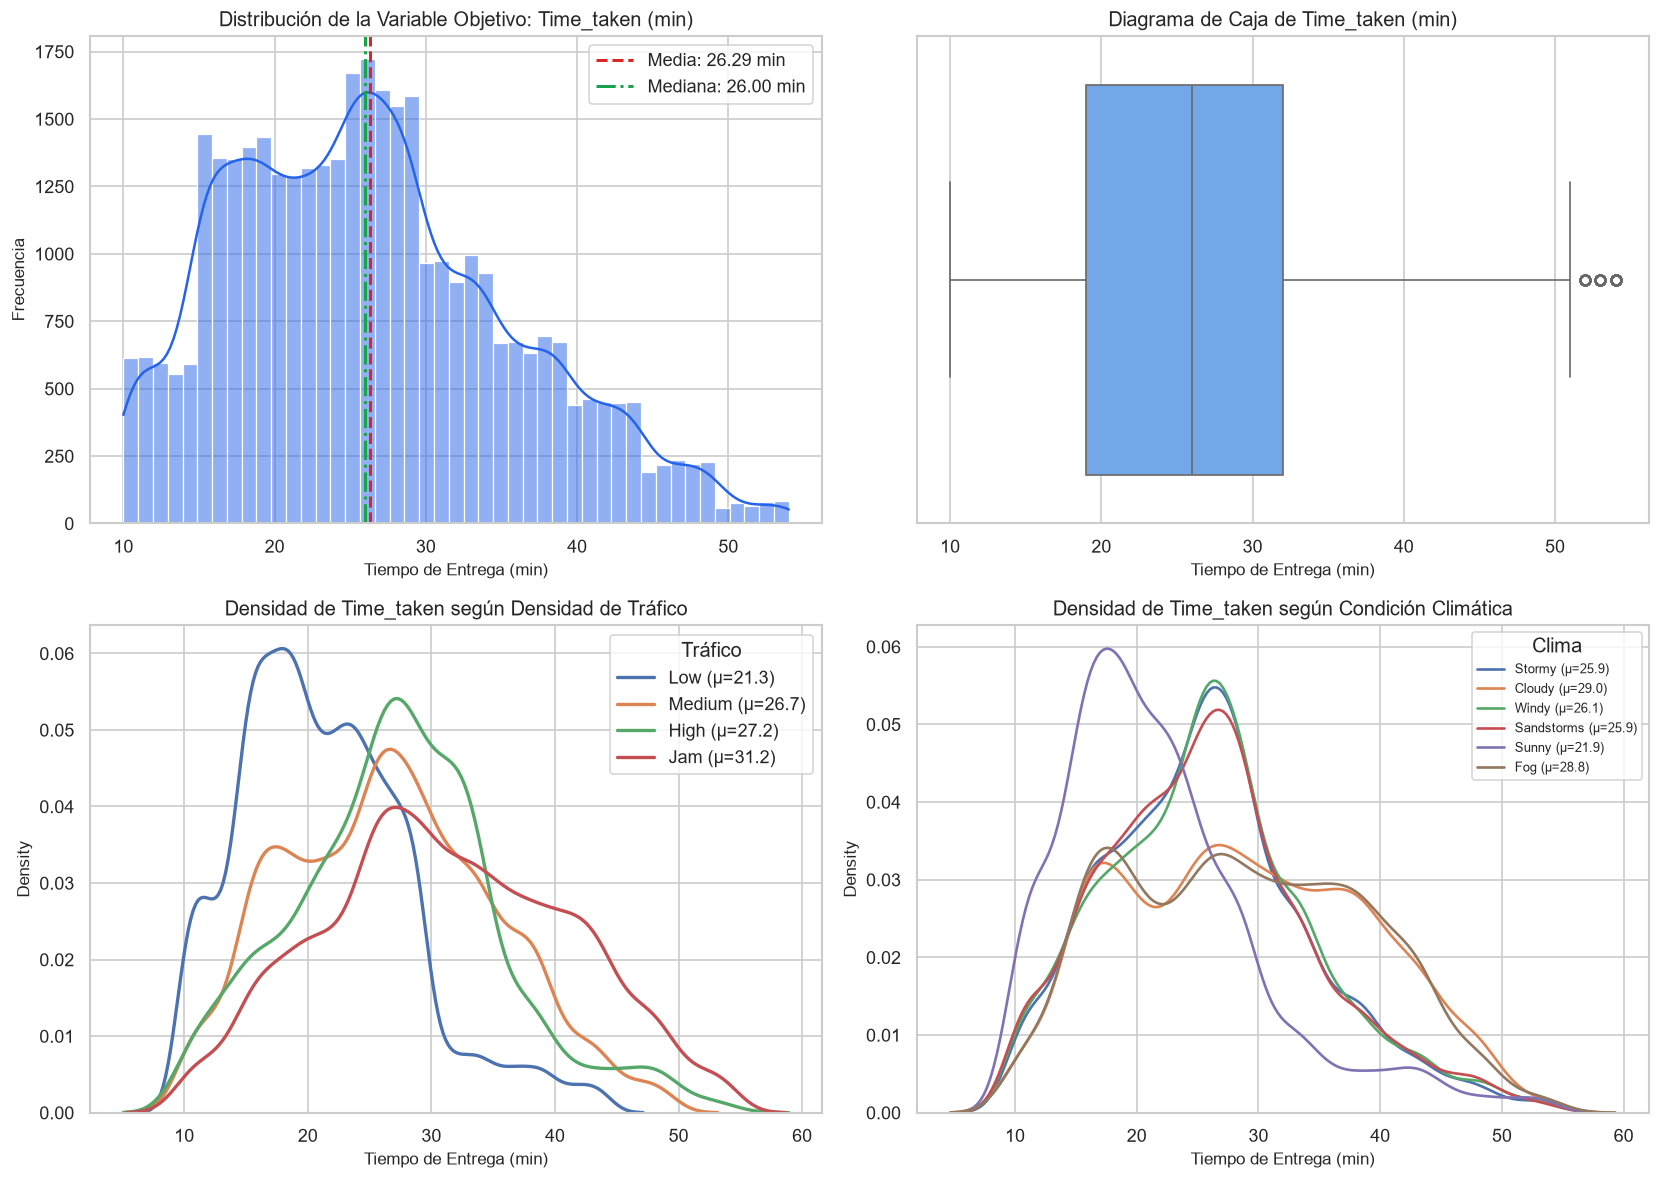

In [8]:
target = train_df["Time_taken (min)"]
print(
    f"Time_taken (min) -> Media: {target.mean():.2f} | Mediana: {target.median():.2f} | "
    f"Std: {target.std():.2f} | Min: {target.min()} | Max: {target.max()} | "
    f"P90: {target.quantile(0.90):.1f} | >40 min: {(target > 40).mean()*100:.2f}%"
)

# Preparar copias limpias temporales solo para graficar sin 'NaN' texto
eda_df = train_df.copy()
for c in ["Weather_conditions", "Road_traffic_density", "Festival", "City", "Type_of_vehicle", "Type_of_order"]:
    eda_df[c] = eda_df[c].astype(str).str.strip().replace({"NaN": np.nan, "nan": np.nan})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histograma + KDE
sns.histplot(target, bins=45, kde=True, color="#2563EB", ax=axes[0, 0])
axes[0, 0].axvline(target.mean(), color="#DC2626", linestyle="--", linewidth=1.8, label=f"Media: {target.mean():.2f} min")
axes[0, 0].axvline(target.median(), color="#16A34A", linestyle="-.", linewidth=1.8, label=f"Mediana: {target.median():.2f} min")
axes[0, 0].set_title("Distribución de la Variable Objetivo: Time_taken (min)")
axes[0, 0].set_xlabel("Tiempo de Entrega (min)")
axes[0, 0].set_ylabel("Frecuencia")
axes[0, 0].legend()

# 2. Boxplot horizontal del target
sns.boxplot(x=target, color="#60A5FA", ax=axes[0, 1])
axes[0, 1].set_title("Diagrama de Caja de Time_taken (min)")
axes[0, 1].set_xlabel("Tiempo de Entrega (min)")

# 3. KDE por nivel de tráfico
traffic_order = ["Low", "Medium", "High", "Jam"]
for lvl in traffic_order:
    subset = eda_df.loc[eda_df["Road_traffic_density"] == lvl, "Time_taken (min)"]
    sns.kdeplot(subset, label=f"{lvl} (μ={subset.mean():.1f})", linewidth=2, ax=axes[1, 0])
axes[1, 0].set_title("Densidad de Time_taken según Densidad de Tráfico")
axes[1, 0].set_xlabel("Tiempo de Entrega (min)")
axes[1, 0].legend(title="Tráfico")

# 4. KDE por condiciones climáticas
for w in eda_df["Weather_conditions"].dropna().unique():
    subset = eda_df.loc[eda_df["Weather_conditions"] == w, "Time_taken (min)"]
    sns.kdeplot(subset, label=f"{w} (μ={subset.mean():.1f})", linewidth=1.6, ax=axes[1, 1])
axes[1, 1].set_title("Densidad de Time_taken según Condición Climática")
axes[1, 1].set_xlabel("Tiempo de Entrega (min)")
axes[1, 1].legend(title="Clima", fontsize=8)

plt.tight_layout()
fig.savefig(FIG_DIR / "01_distribucion_tiempos.png", bbox_inches="tight")
plt.show()


### Análisis Bivariado por Variables Contextuales y Operativas
Cuantificación el impacto medio y la dispersión de `Time_taken (min)` a través de tráfico, clima, entregas múltiples, festivales, condición del vehículo y tipo de ciudad.



Resumen Time_taken (min) por Road_traffic_density:


,count,mean,median,std
Road_traffic_density,,,,
Low,12358,21.30,20.0,6.85
Medium,8843,26.67,26.0,8.53
High,3535,27.25,27.0,8.41
Jam,11249,31.17,31.0,9.96



Resumen Time_taken (min) por Weather_conditions:


,count,mean,median,std
Weather_conditions,,,,
Cloudy,6014,28.97,28.5,10.13
Fog,6156,28.82,28.0,10.10
Sandstorms,6005,25.86,26.0,8.65
Stormy,6104,25.88,26.0,8.48
Sunny,5807,21.91,20.0,8.32
Windy,5888,26.08,26.0,8.60



Resumen Time_taken (min) por multiple_deliveries:


,count,mean,median,std
multiple_deliveries,,,,
0.0,11282,22.89,22.0,8.77
1.0,22528,26.84,26.0,8.54
2.0,1581,40.53,40.0,4.99
3.0,286,47.86,48.0,3.49


... (2 outputs left out)


Resumen Time_taken (min) por Vehicle_condition:


,count,mean,median,std
Vehicle_condition,,,,
0,12020,30.08,28.0,9.61
1,11981,24.32,24.0,8.71
2,12054,24.48,24.0,8.63
3,412,26.48,26.0,9.47



Resumen Time_taken (min) por City:


,count,mean,median,std
City,,,,
Semi-Urban,122,49.89,49.0,2.74
Urban,8147,22.99,22.0,8.82
Metropolitian,27241,27.33,26.0,9.20


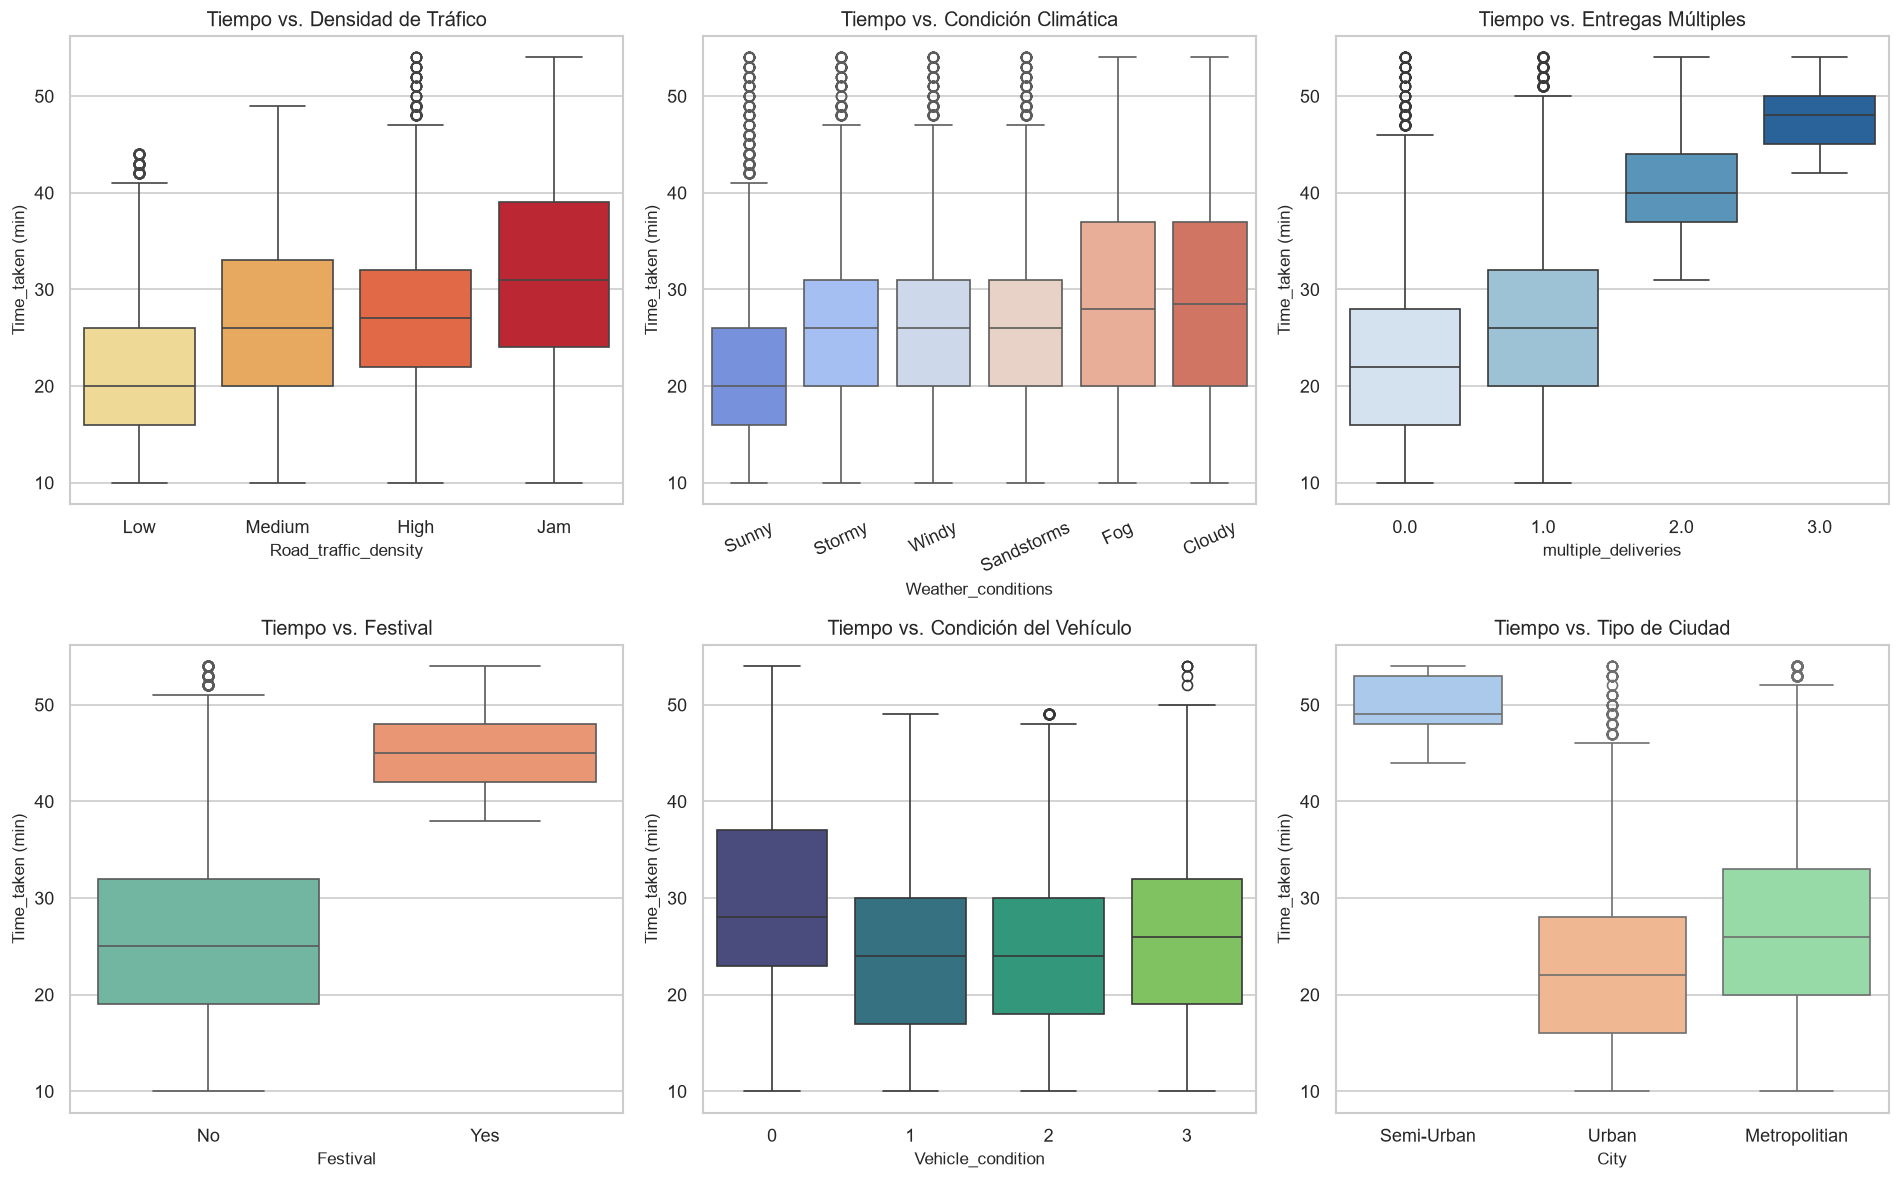

In [9]:
for col, order in [
    ("Road_traffic_density", ["Low", "Medium", "High", "Jam"]),
    ("Weather_conditions", None),
    ("multiple_deliveries", [0.0, 1.0, 2.0, 3.0]),
    ("Festival", ["No", "Yes"]),
    ("Vehicle_condition", [0, 1, 2, 3]),
    ("City", ["Semi-Urban", "Urban", "Metropolitian"]),
]:
    grp = eda_df.groupby(col)["Time_taken (min)"].agg(["count", "mean", "median", "std"]).round(2)
    if order is not None:
        grp = grp.reindex([x for x in order if x in grp.index])
    print(f"\nResumen Time_taken (min) por {col}:")
    display(grp)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

sns.boxplot(data=eda_df, x="Road_traffic_density", y="Time_taken (min)", order=traffic_order, palette="YlOrRd", ax=axes[0, 0])
axes[0, 0].set_title("Tiempo vs. Densidad de Tráfico")

weather_order = eda_df.groupby("Weather_conditions")["Time_taken (min)"].median().sort_values().index.tolist()
sns.boxplot(data=eda_df, x="Weather_conditions", y="Time_taken (min)", order=weather_order, palette="coolwarm", ax=axes[0, 1])
axes[0, 1].set_title("Tiempo vs. Condición Climática")
axes[0, 1].tick_params(axis="x", rotation=25)

sns.boxplot(data=eda_df, x="multiple_deliveries", y="Time_taken (min)", palette="Blues", ax=axes[0, 2])
axes[0, 2].set_title("Tiempo vs. Entregas Múltiples")

sns.boxplot(data=eda_df, x="Festival", y="Time_taken (min)", order=["No", "Yes"], palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("Tiempo vs. Festival")

sns.boxplot(data=eda_df, x="Vehicle_condition", y="Time_taken (min)", palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("Tiempo vs. Condición del Vehículo")

sns.boxplot(data=eda_df, x="City", y="Time_taken (min)", order=["Semi-Urban", "Urban", "Metropolitian"], palette="pastel", ax=axes[1, 2])
axes[1, 2].set_title("Tiempo vs. Tipo de Ciudad")

plt.tight_layout()
fig.savefig(FIG_DIR / "01b_eda_bivariado_operativo.png", bbox_inches="tight")
plt.show()
